# Task 4.6


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from scipy.optimize import minimize
from scipy.special import expit

threadpool_limits(limits=1)
FAST = True


In [2]:
def folds(n, k, rng):
    fs = np.array_split(rng.permutation(n), k)
    out = []
    for i in range(k):
        tr = np.concatenate([fs[j] for j in range(k) if j != i])
        out.append((tr, fs[i]))
    return out


def loss(w, z, y, l=0):
    s = y * (z @ w)
    p = w.copy()
    p[0] = 0
    e = np.mean(np.logaddexp(0, -s)) + l*(p @ p)
    g = z.T @ (-y * expit(-s)) / len(y) + 2*l*p
    return e, g


def l2(z, y, l, w=None):
    if w is None:
        w = np.zeros(z.shape[1])
    res = minimize(loss, w, args=(z, y, l), method='L-BFGS-B', jac=True,
                   options=dict(gtol=1e-8, ftol=1e-14, maxiter=10000, maxls=50))
    assert res.success or np.max(np.abs(res.jac)) < 1e-5
    return res.x


def bias(x):
    return np.column_stack([np.ones(len(x)), x])


def std(x, m=None, s=None):
    if m is None:
        m = x.mean(axis=0)
        s = x.std(axis=0)
        s = np.where(s < 1e-12, 1, s)
    return (x - m) / s, m, s


def corr(x, y, n=20):
    x = x - x.mean(axis=0)
    y = y - y.mean()
    d = np.sqrt(np.sum(x**2, axis=0) * (y @ y))
    c = np.divide(np.abs(x.T @ y), d, out=np.zeros(x.shape[1]), where=d > 0)
    return np.argsort(-c, kind='stable')[:n]


def pred(s):
    return np.where(s >= 0, 1, -1)


def stat(x, axis=0):
    x = np.asarray(x)
    return x.mean(axis=axis), x.std(axis=axis, ddof=1) / np.sqrt(x.shape[axis])


In [3]:
R = 100 if FAST else 200
rng = np.random.default_rng(407)
err = np.zeros((R, 2))

for r in range(R):
    x = rng.normal(size=(50, 1000))
    y = rng.choice([-1, 1], size=50)
    all_cols = corr(x, y, 20)
    fs = folds(50, 10, rng)
    for tr, va in fs:
        cols0 = corr(x[tr], y[tr], 20)
        for j, cols in enumerate([all_cols, cols0]):
            train_X, m, sd = std(x[tr][:, cols])
            valid_X, _, _ = std(x[va][:, cols], m, sd)
            w = l2(bias(train_X), y[tr], 0.01)
            yp = pred(bias(valid_X) @ w)
            err[r, j] += np.sum(yp != y[va]) / 50
    if (r + 1) % 20 == 0:
        print(f"Completed snooping run {r + 1}/{R}", flush=True)

m, se = stat(err)
gm, gs = stat(err[:, 1] - err[:, 0])
for j, lab in enumerate(["Global selection (leaked)", "Selection inside folds"]):
    print(f"{lab}: {m[j]:.5f} +/- {se[j]:.5f} SE, n={R}")
print(f"Paired error gap: {gm:.5f} +/- {gs:.5f} SE")


Completed snooping run 20/100
Completed snooping run 40/100
Completed snooping run 60/100
Completed snooping run 80/100
Completed snooping run 100/100
Global selection (leaked): 0.08580 +/- 0.00469 SE, n=100
Selection inside folds: 0.50140 +/- 0.01020 SE, n=100
Paired error gap: 0.41560 +/- 0.00952 SE


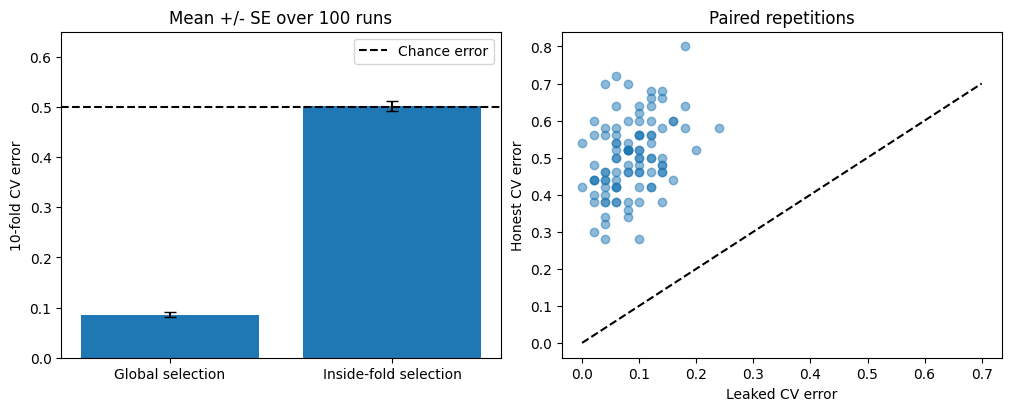

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axs[0].bar([0, 1], m, yerr=se, capsize=4)
axs[0].set_xticks([0, 1], ["Global selection", "Inside-fold selection"])
axs[0].axhline(0.5, color="black", linestyle="--", label="Chance error")
axs[0].set(ylim=(0, 0.65), ylabel="10-fold CV error", title=f"Mean +/- SE over {R} runs")
axs[0].legend()
axs[1].scatter(err[:, 0], err[:, 1], alpha=0.5)
axs[1].plot([0, 0.7], [0, 0.7], "k--")
axs[1].set(xlabel="Leaked CV error", ylabel="Honest CV error", title="Paired repetitions")
plt.show()
